# Homework 5: Deep DOA estimation using a single snapshot

### ELEC-E5481 - Machine Learning for Signal Processing
Write down your name and student number below:<br>
Name: **XXXX** <br>
Student number: **XXXX**

AI tools may be used for:
* debugging
* checking syntax
* clarifying concepts
* generating parts of the codes

You must provide an explanation  how you used AI and which functions or parts are AI generated. It is important that you document the codes, understand all parts of it fully (i.e., can explain what it does and why). The code needs to run and provide the results that are presented in the notebook.  This notebook will be your "project report". 

If there is a reason to believe that the AI policy has not been followed, you may be asked to meet with the TA and lecturer to explain your solution. You should be able to discuss your code, reasoning, and approach in detail. Inability to do so will be considered evidence that the work is not your own, and may lead to academic integrity procedures.

In [3]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Project
Implement approach described in the paper PERFORMANCE ADVANTAGES OF DEEP NEURAL NETWORKS FOR ANGLE OF
ARRIVAL ESTIMATION (this was one of the approaches of the group presentations). The paper is also in mycourses.

**You can follow the architecture exactly or make some modifications (with an aim of making the mode work better: having better RMSE performance, having better source detection performance, etc.)** 

Some guidelines: 
* the architecture needs to be **MLP** as in the paper, but you can improvise: in the number of layers used, in number of neurons in the layers, what activation functions you use, what type of tricks you use in the MLP architecture, training, or what loss is used for training, etc.  
* you can keep the same idea of predicting the max 4 sources
* **Do not to put all your code inside the notebook**.  Instead, place most of your implementation in separate `.py` files and simply import the necessary functions or classes into the notebook. The notebook should serve primarily as your **report**: a place where you explain your reasoning, visualize your results, and demonstrate how you are using the code, not where you write the entire project logic. See also comment below. 
* Explain in the report some details of where and how you trained. How many parameters the model has, etc. How difficult it was to train.  
* **Describe the percentage of AI code**  that you used to accomplish the task. For example: **approximate percentage of AI code is 60%**. This is compulsory to report. 
* Save the  final model (`torch.save`), and  attach it in your submission. There is 400MB upload limit in mycourses but I think you should be able to manage without exceeding that size. If your model larger, then just send me an email. 

Grading:
* not super easy to make the approach work....
* we put also emphasis on **learning curve**. You can explain in your report why you could not make it work and what have you learned during the process. 
* _Report can be good even when the results are not stunishing!_ 
* Some ideas of how grading is done is provided form rubric.

**Note:** Aalto offers computer rooms with GPU-machines. You can also think of some other possible resources: Google collab, Kaggle notebook,etc.  However, the model (as described in the paper) is small and can be trained in a laptop. 

_Note_: Below is an example of a good file structure how deep learning codepackages are structured in resarch papers and open-source projects. 

```

project/
├── models/
│   └── network.py
├── data/
│   └── dataloader.py
├── training/
│   ├── trainer.py
│   └── utils.py
├── experiments/
│   └── run_experiment.py
└── report.ipynb
```

The file `data_generation.py` provides an example of data generation which you can adopt/edit to get started. 

## Models

The networks are trained in `train.ipynb` and saved to `models/<name>/`. Each model is tested on its scenario:
* **A**: FOV 50°, amplitudes $U[0.5, 1.5]$ (paper Figs. 3, 6, 7)
* **B**: FOV 20°, equal gains (paper Fig. 2)

In [4]:
import json

import torch

from src.models import BaseDOAModel,ResidualHeadModel
from src.evaluation import compute_baselines, compute_models, evaluate_per_snr, plot_learning_curve, plot_paper_figures, plot_results

# name: scenario, network (weights from models/<name>/best.pth)
MODELS = {
    "A": dict(scenario="A", model=BaseDOAModel(d_model=32, input_norm=True)),
    "B": dict(scenario="B", model=BaseDOAModel(d_model=32, input_norm=True)),
    "A_res": dict(scenario="A", model=ResidualHeadModel(d_model=32, input_norm=True)),
    
}
for name, m in MODELS.items():
    m["model"].load_state_dict(torch.load(f"models/{name}/best.pth"))

## Learning curves

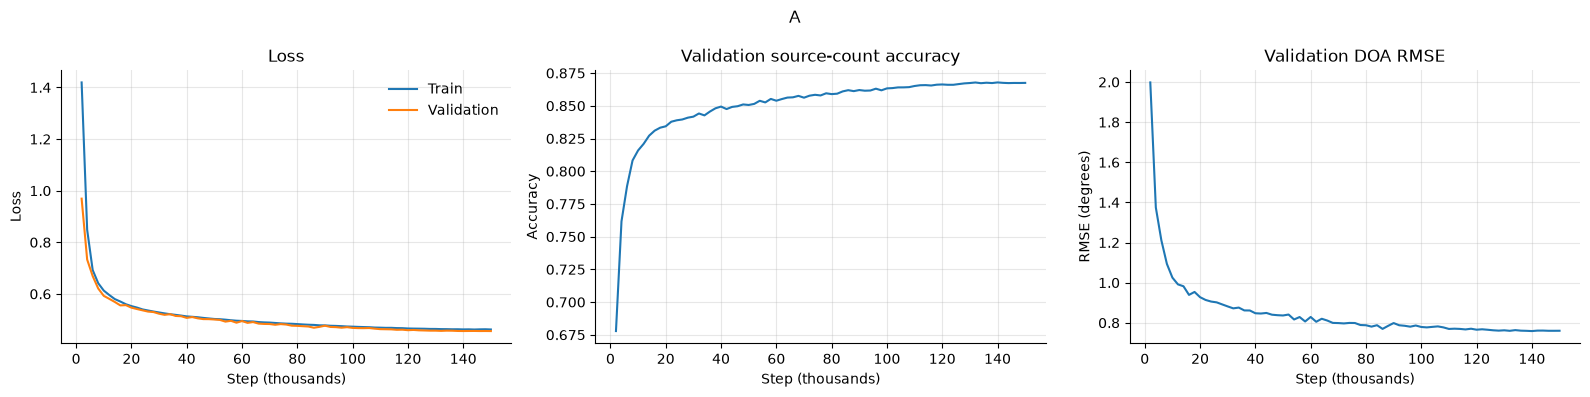

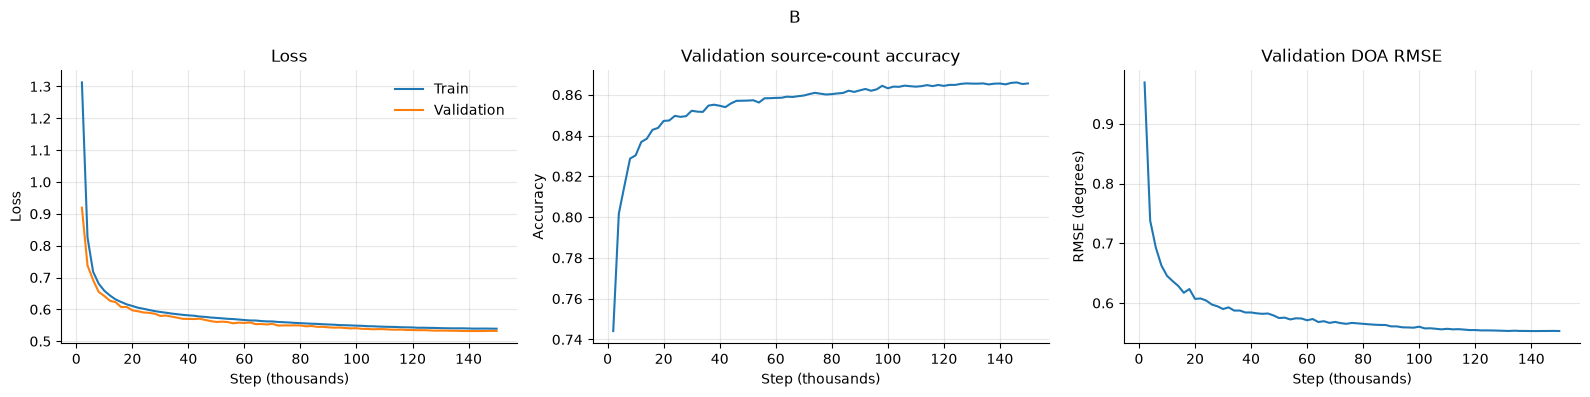

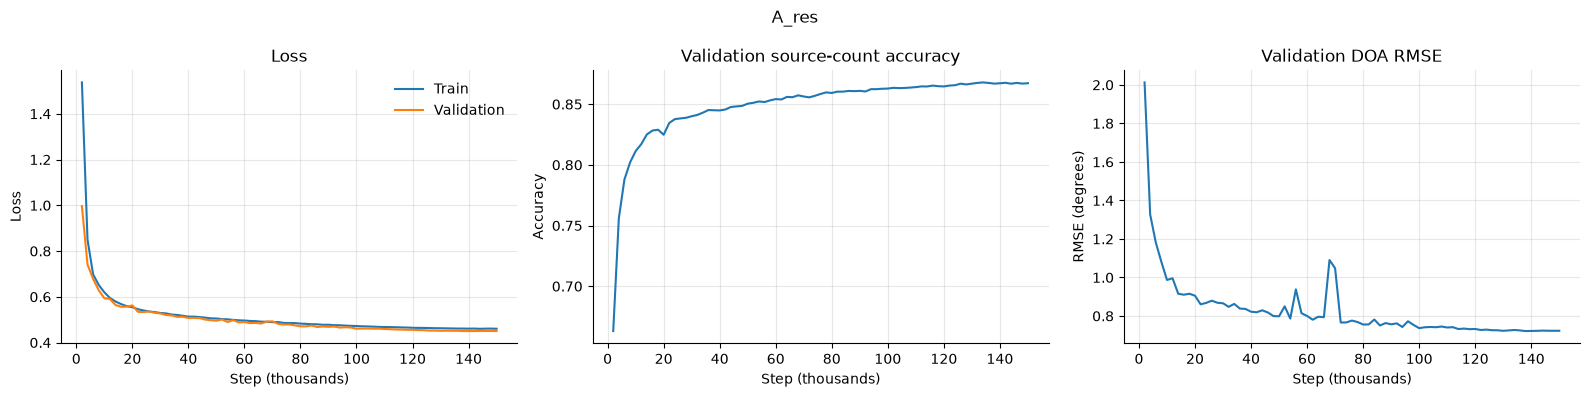

In [5]:
for name in MODELS:
    with open(f"models/{name}/history.json") as f:
        plot_learning_curve(json.load(f), title=name)

## Test results

Same test set for every model: 1000 realizations per SNR and number of sources $K$. RMSE is the paper's Eq. 3 (each true angle vs. its closest estimate), using the head of the true $K$.

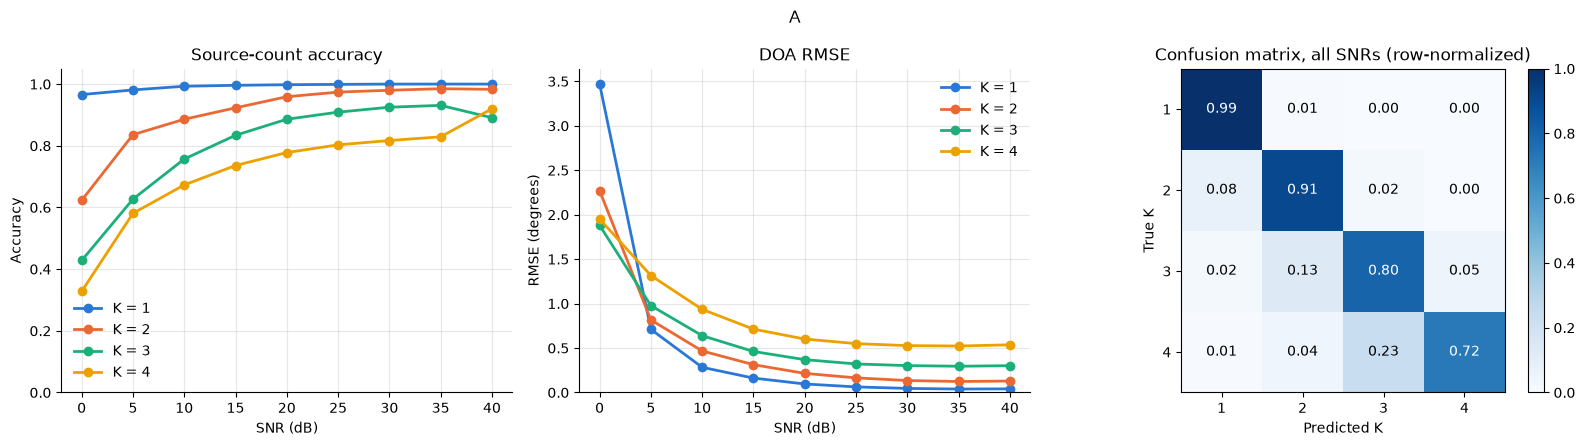

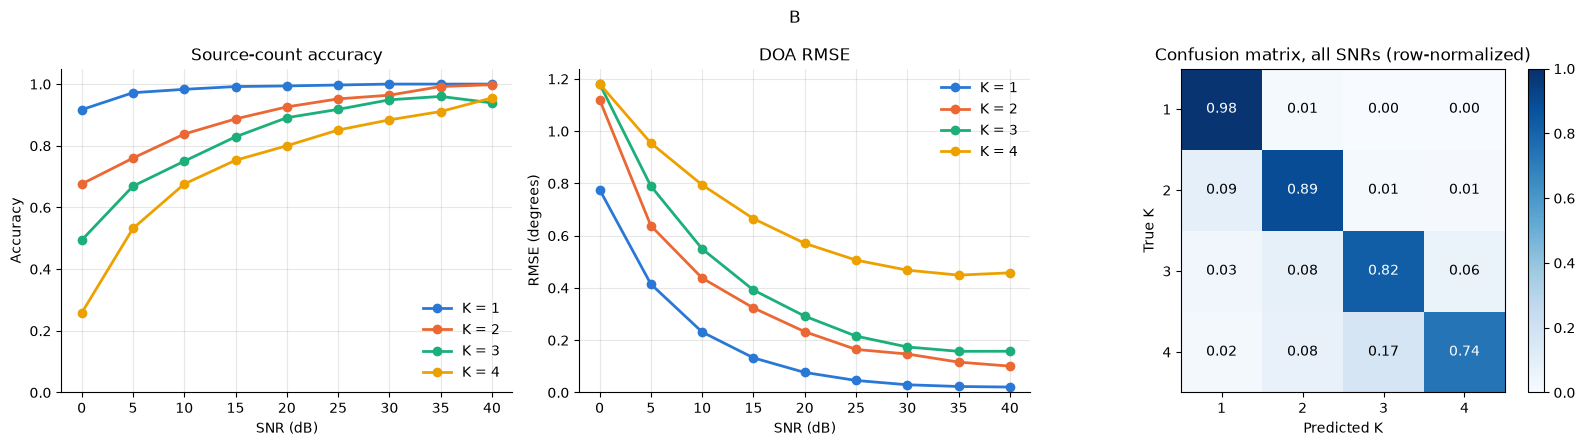

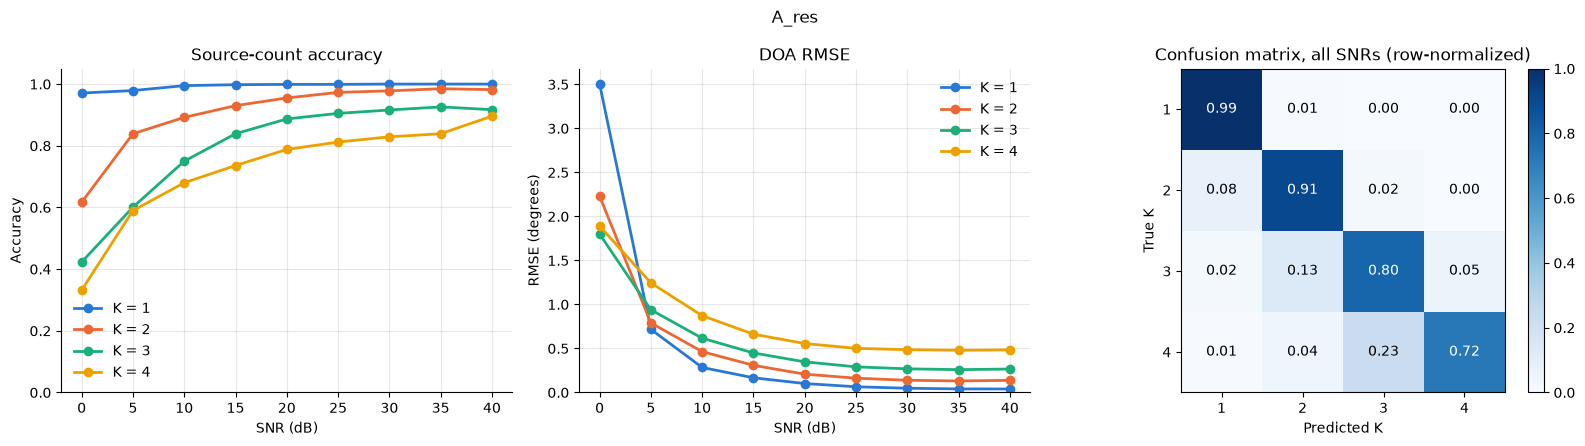

In [6]:
for name, m in MODELS.items():
    plot_results(evaluate_per_snr(m["model"], m["scenario"]), title=name)

## Paper figures

Reference methods (solid, `src/baselines.py`) and the models (dashed). Fig. 4 (other architectures) is not replicated. The reference methods take ~5 min the first time and are then loaded from `results/baselines.json` (delete it to recompute).

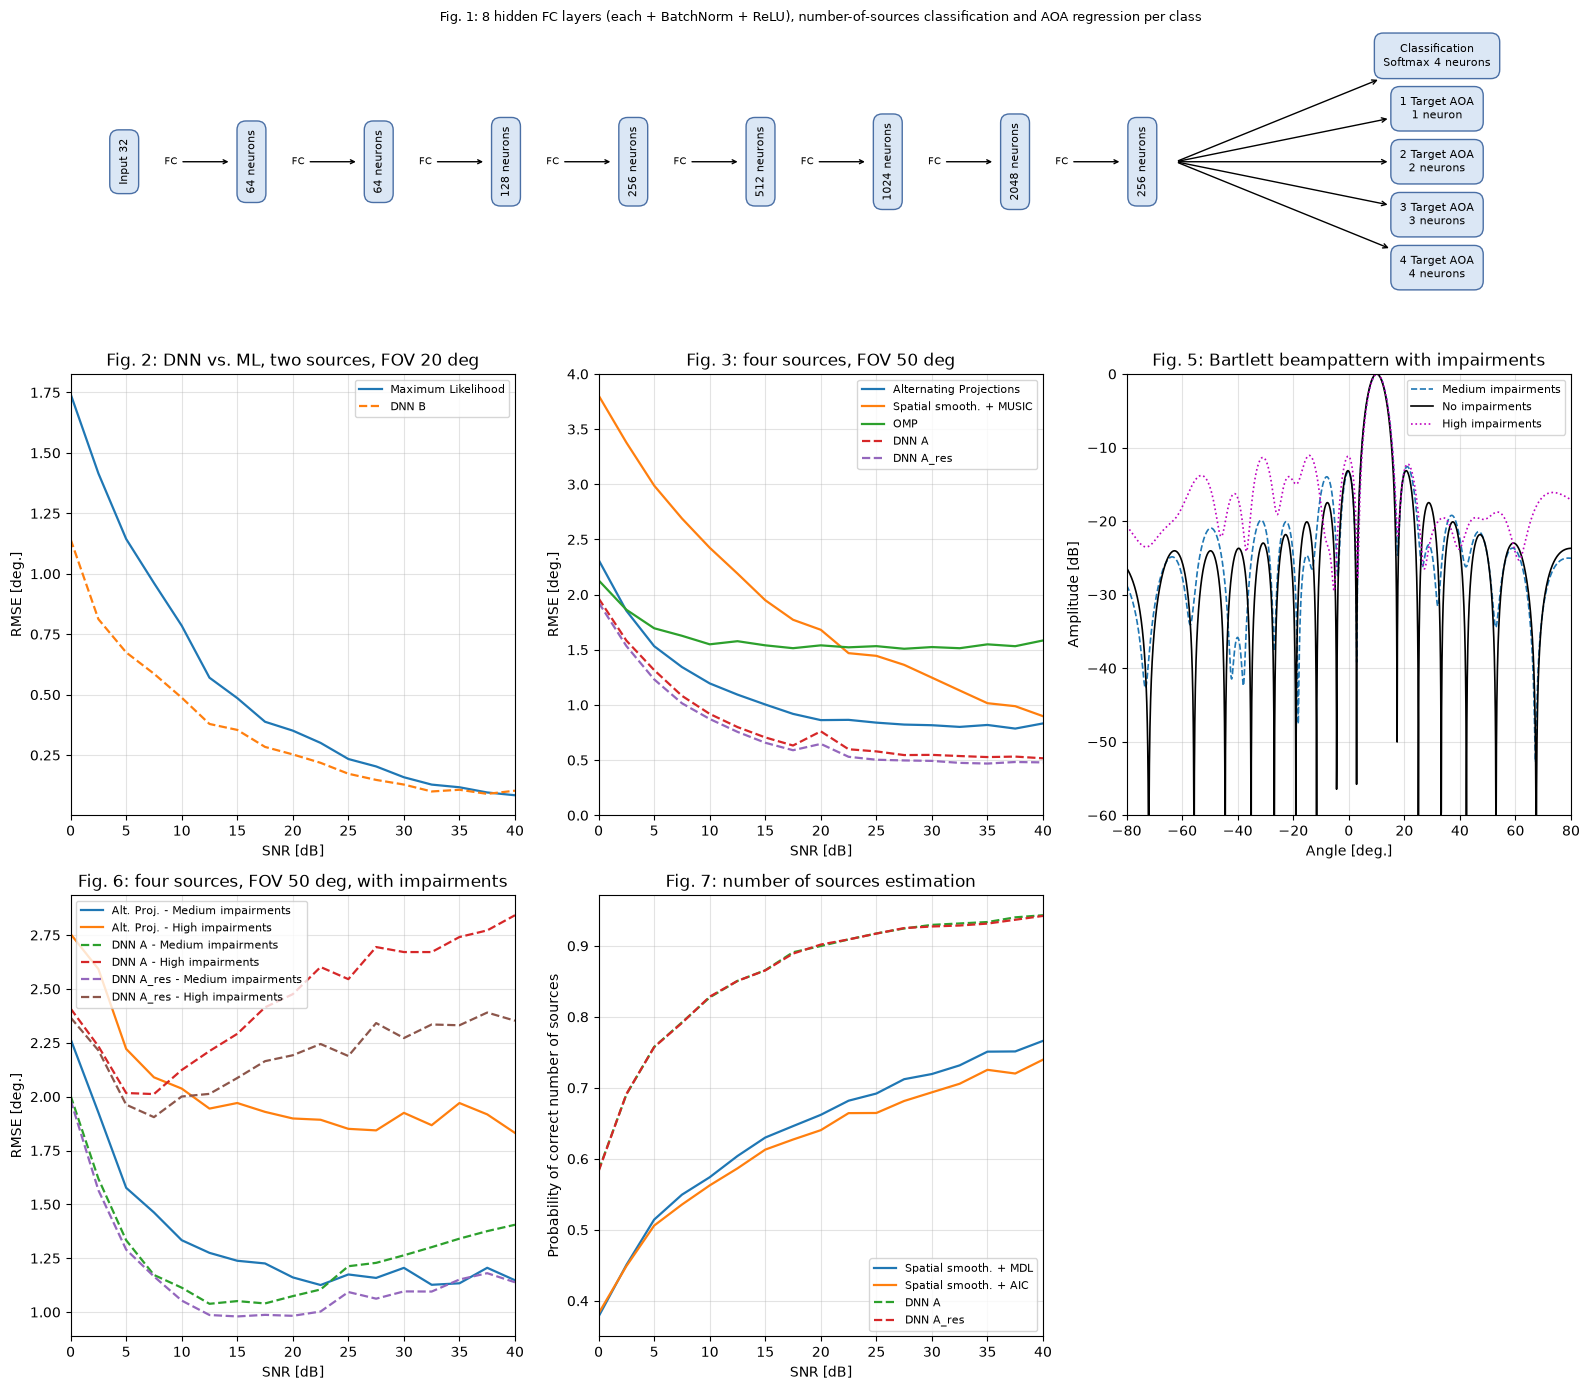

In [7]:
baselines = compute_baselines()  # loaded from results/baselines.json after the first run
plot_paper_figures(baselines, compute_models(MODELS))